# Predictive Customer Churn Classifier: Random Forest vs. XGBoost

**Machine Learning & Data Science Internship Task 3**

Predict which telecom customers will **cancel their subscription (churn)** using the IBM Telco Customer Churn
dataset (7,043 customers, 21 columns). Only about 1 in 4 customers churns, so the classes are **imbalanced**,
and we optimise **ROC-AUC** (target: above 0.80) rather than plain accuracy.

**Workflow**
1. Load the data and convert `TotalCharges` to numeric, handling the resulting nulls
2. EDA: churn rate, churn by contract / internet service / payment method, tenure and charges distributions
3. Stratified 80/20 split, then `OneHotEncoder` for categorical columns and `StandardScaler` for numeric ones
4. Handle class imbalance in two ways:
   - **Random Forest + SMOTE** (synthetic oversampling of churners, applied to training folds only)
   - **XGBoost + `scale_pos_weight`** (class weighting inside the loss function)
5. Tune both with 5-fold stratified cross-validation (`GridSearchCV`, scored by ROC-AUC)
6. Evaluate on the test set: ROC-AUC, classification report, confusion matrices, ROC curves
7. Extract and compare the **top 10 most influential features**

## 1. Setup and imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

# imbalanced-learn's Pipeline lets SMOTE run only on training data (never on validation or test data)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

## 2. Load the dataset

The IBM Telco Customer Churn CSV is stored in `../data/`; if it is missing, the notebook downloads it from IBM's
public GitHub repository.

In [2]:
DATA_PATH = Path("../data/telco_customer_churn.csv")
DATA_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
            "master/data/Telco-Customer-Churn.csv")

df = pd.read_csv(DATA_PATH) if DATA_PATH.exists() else pd.read_csv(DATA_URL)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Data cleaning

`TotalCharges` is stored as text because some rows contain a blank space instead of a number. We convert it with
`pd.to_numeric(errors="coerce")`, which turns those blanks into `NaN`.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

null_rows = df[df["TotalCharges"].isnull()]
print(f"Rows with missing TotalCharges: {len(null_rows)}")
null_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows with missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Every missing `TotalCharges` belongs to a customer with **tenure = 0**: they have just signed up and have not
been billed yet. The correct value is therefore **0**, not the mean or median.

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is just an identifier with no predictive value
df = df.drop(columns="customerID")

# Encode the target: 1 = churned, 0 = stayed
df["Churn"] = (df["Churn"] == "Yes").astype(int)

print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


## 4. Exploratory data analysis

### 4.1 Class imbalance

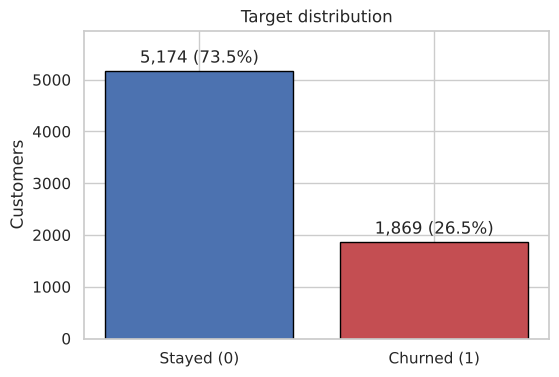

Churn rate: 26.54%  ->  imbalance ratio about 2.8 : 1


In [6]:
churn_rate = df["Churn"].mean()
counts = df["Churn"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Stayed (0)", "Churned (1)"], counts.values, color=["#4C72B0", "#C44E52"], edgecolor="black")
ax.bar_label(bars, labels=[f"{v:,} ({v / len(df):.1%})" for v in counts.values], padding=3)
ax.set_ylabel("Customers")
ax.set_title("Target distribution")
ax.set_ylim(0, counts.max() * 1.15)
plt.show()

print(f"Churn rate: {churn_rate:.2%}  ->  imbalance ratio about {counts[0] / counts[1]:.1f} : 1")

Only about 26.5% of customers churn. A model that always predicts "stays" would already be about 73% accurate
while being useless, which is why we focus on ROC-AUC, recall and F1 for the churn class.

### 4.2 Churn rate by key categorical features

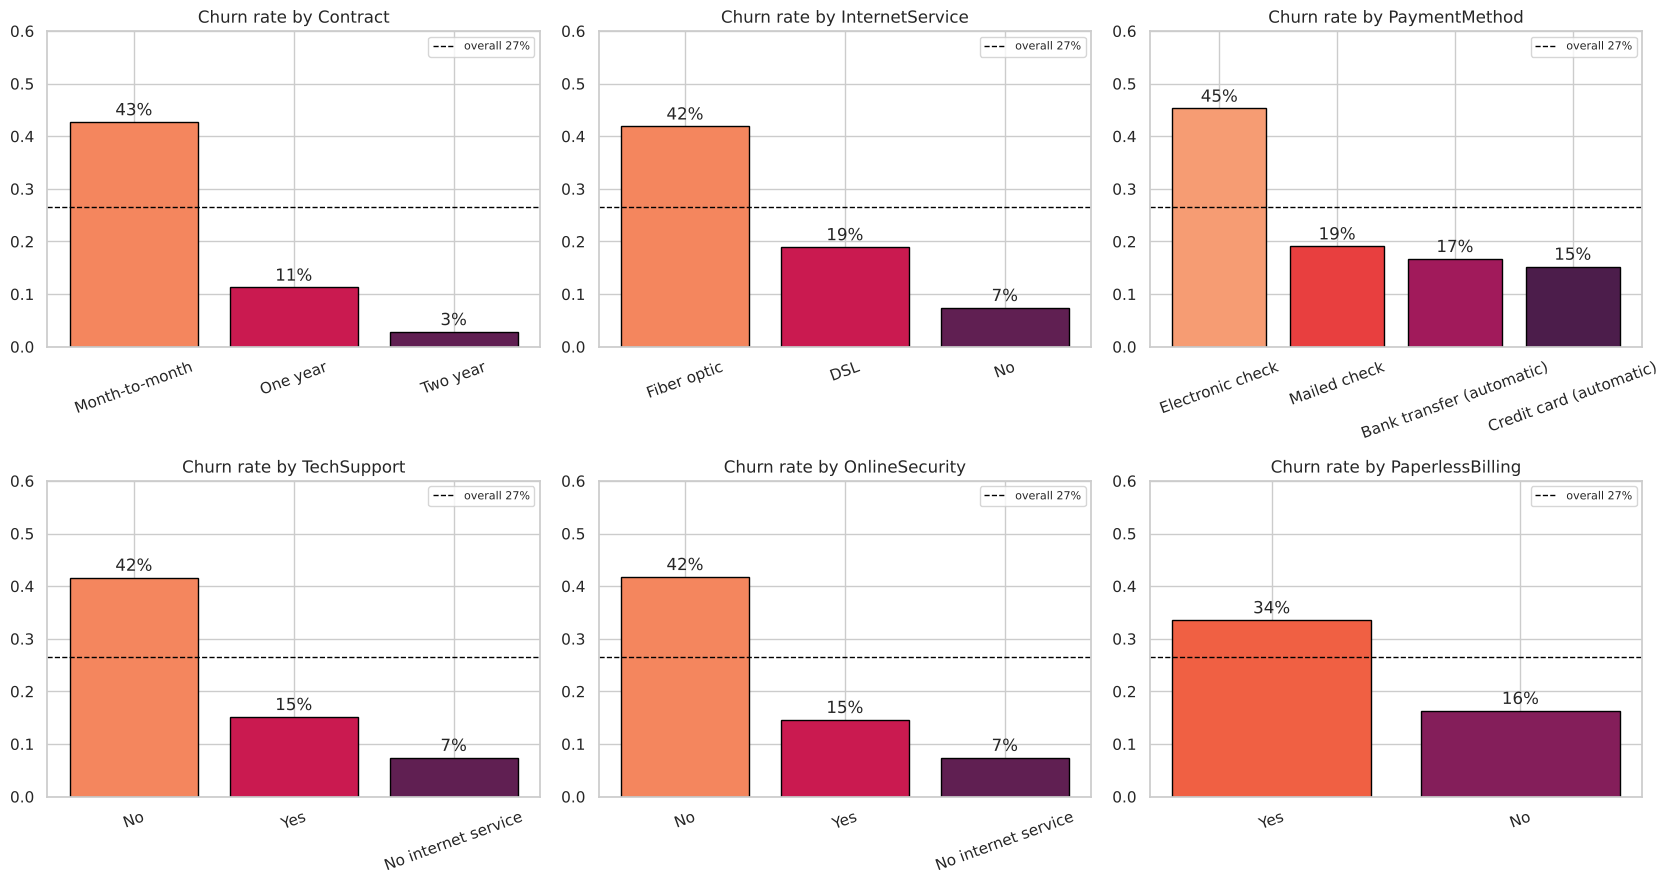

In [7]:
cat_to_plot = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), cat_to_plot):
    rates = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    bars = ax.bar(rates.index, rates.values, color=sns.color_palette("rocket_r", len(rates)), edgecolor="black")
    ax.bar_label(bars, fmt="{:.0%}", padding=2)
    ax.axhline(churn_rate, color="black", ls="--", lw=1, label=f"overall {churn_rate:.0%}")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylim(0, 0.6)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**Observations**
- **Month-to-month contracts** churn far more than one- or two-year contracts.
- **Fiber optic** internet customers churn more than DSL customers.
- Customers paying by **electronic check** churn much more than those on automatic payments.
- Having **no tech support** or **no online security** add-ons is linked to much higher churn.

### 4.3 Numeric features: tenure and charges

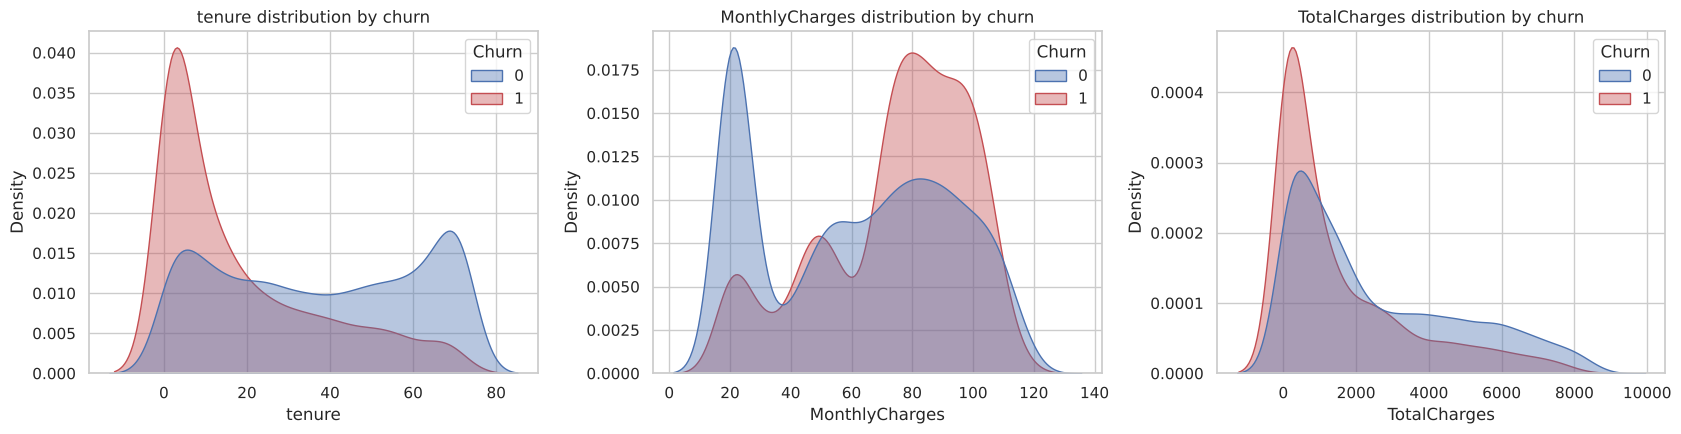

,tenure,MonthlyCharges,TotalCharges
Churn,,,
Stayed,38.0,64.425,1679.525
Churned,10.0,79.650,703.550


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=df, x=col, hue="Churn", fill=True, common_norm=False, alpha=0.4,
                palette={0: "#4C72B0", 1: "#C44E52"}, ax=ax)
    ax.set_title(f"{col} distribution by churn")
plt.tight_layout()
plt.show()

df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median().rename(index={0: "Stayed", 1: "Churned"})

Churners are concentrated among **new customers** (low tenure) and customers with **high monthly charges**.
Their total charges are lower simply because they have not stayed long.

## 5. Train/test split and preprocessing

- **Stratified 80/20 split** keeps the 26.5% churn rate in both sets.
- `OneHotEncoder` converts the 15 text columns into binary indicator columns.
- `StandardScaler` standardises the numeric columns (tree models do not need it, but it does no harm and keeps
  the pipeline reusable for linear models).
- All preprocessing is fitted inside the pipeline, on training folds only.

In [9]:
X = df.drop(columns="Churn")
y = df["Churn"]

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
categorical_features = [c for c in X.columns if c not in numeric_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Training set: {len(X_train):,} rows (churn rate {y_train.mean():.2%})")
print(f"Test set:     {len(X_test):,} rows (churn rate {y_test.mean():.2%})")
print(f"Categorical columns ({len(categorical_features)}):", categorical_features)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

Training set: 5,634 rows (churn rate 26.54%)
Test set:     1,409 rows (churn rate 26.54%)
Categorical columns (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 6. Model training with cross-validation

We tune each model with `GridSearchCV` over **5-fold stratified cross-validation**, scored by ROC-AUC.

### 6.1 Random Forest + SMOTE

SMOTE creates synthetic churners by interpolating between real churners and their nearest neighbours, until both
classes are the same size. Because it sits **inside** the imblearn pipeline, it is applied only to the training
part of each fold; validation folds and the test set keep their real class distribution.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_pipeline = ImbPipeline([
    ("prep", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    # n_jobs=1 here because GridSearchCV already runs the folds in parallel
    ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
])

rf_search = GridSearchCV(
    rf_pipeline,
    param_grid={
        "model__max_depth": [8, 12],
        "model__min_samples_leaf": [1, 5],
    },
    scoring="roc_auc", cv=cv, n_jobs=-1,
)
rf_search.fit(X_train, y_train)
print("Best parameters:", rf_search.best_params_)

Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 5}


### 6.2 XGBoost + `scale_pos_weight`

Instead of creating synthetic rows, XGBoost can **weight** the minority class in its loss function.
Setting `scale_pos_weight = (number of non-churners) / (number of churners)` makes each churner count about
2.8 times as much as a non-churner.

In [11]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.3f}")

xgb_pipeline = ImbPipeline([
    ("prep", preprocessor),
    ("model", XGBClassifier(
        n_estimators=300, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight, eval_metric="auc",
        random_state=RANDOM_STATE, n_jobs=1,
    )),
])

xgb_search = GridSearchCV(
    xgb_pipeline,
    param_grid={
        "model__max_depth": [3, 5],
        "model__learning_rate": [0.03, 0.1],
    },
    scoring="roc_auc", cv=cv, n_jobs=-1,
)
xgb_search.fit(X_train, y_train)
print("Best parameters:", xgb_search.best_params_)

scale_pos_weight = 2.769


Best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 3}


### 6.3 Cross-validation results

In [12]:
searches = {"Random Forest + SMOTE": rf_search, "XGBoost + scale_pos_weight": xgb_search}

cv_rows = []
for name, search in searches.items():
    res = search.cv_results_
    i = search.best_index_
    fold_scores = [res[f"split{k}_test_score"][i] for k in range(cv.get_n_splits())]
    cv_rows.append({"Model": name, "CV ROC-AUC mean": np.mean(fold_scores),
                    "CV ROC-AUC std": np.std(fold_scores),
                    "Fold scores": np.round(fold_scores, 4).tolist()})

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round(4)

,CV ROC-AUC mean,CV ROC-AUC std,Fold scores
Model,,,
Random Forest + SMOTE,0.8438,0.0091,"[0.8367, 0.8334, 0.8393, 0.8558, 0.8536]"
XGBoost + scale_pos_weight,0.8493,0.0113,"[0.8433, 0.8329, 0.847, 0.8651, 0.8583]"


## 7. Test-set evaluation

The models output a churn **probability**. ROC-AUC uses those probabilities directly; the classification metrics
below use the default 0.5 threshold.

In [13]:
models = {name: search.best_estimator_ for name, search in searches.items()}
probas, preds = {}, {}

rows = []
for name, model in models.items():
    probas[name] = model.predict_proba(X_test)[:, 1]
    preds[name] = (probas[name] >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, probas[name]),
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision (churn)": precision_score(y_test, preds[name]),
        "Recall (churn)": recall_score(y_test, preds[name]),
        "F1 (churn)": f1_score(y_test, preds[name]),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,ROC-AUC,Accuracy,Precision (churn),Recall (churn),F1 (churn)
Model,,,,,
Random Forest + SMOTE,0.8376,0.7630,0.5403,0.7166,0.6161
XGBoost + scale_pos_weight,0.8468,0.7502,0.5191,0.7995,0.6295


In [14]:
TARGET_AUC = 0.80
for name, auc in results["ROC-AUC"].items():
    status = "PASS" if auc > TARGET_AUC else "FAIL"
    print(f"[{status}] {name}: test ROC-AUC = {auc:.4f} (target > {TARGET_AUC})")

[PASS] Random Forest + SMOTE: test ROC-AUC = 0.8376 (target > 0.8)
[PASS] XGBoost + scale_pos_weight: test ROC-AUC = 0.8468 (target > 0.8)


In [15]:
for name in models:
    print("=" * 62)
    print(f"Classification report: {name}")
    print("=" * 62)
    print(classification_report(y_test, preds[name], target_names=["Stayed", "Churned"], digits=4))

Classification report: Random Forest + SMOTE
              precision    recall  f1-score   support

      Stayed     0.8839    0.7797    0.8285      1035
     Churned     0.5403    0.7166    0.6161       374

    accuracy                         0.7630      1409
   macro avg     0.7121    0.7481    0.7223      1409
weighted avg     0.7927    0.7630    0.7722      1409

Classification report: XGBoost + scale_pos_weight
              precision    recall  f1-score   support

      Stayed     0.9100    0.7324    0.8116      1035
     Churned     0.5191    0.7995    0.6295       374

    accuracy                         0.7502      1409
   macro avg     0.7145    0.7659    0.7205      1409
weighted avg     0.8062    0.7502    0.7632      1409



### 7.1 ROC curves

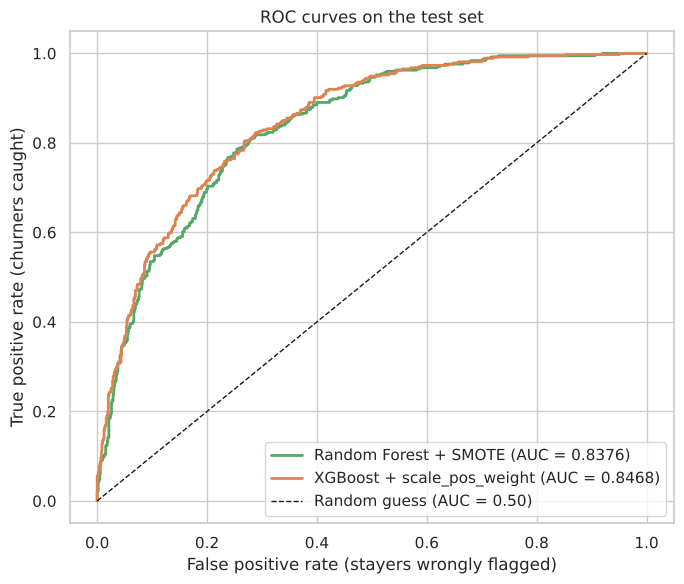

In [16]:
colors = {"Random Forest + SMOTE": "#55A868", "XGBoost + scale_pos_weight": "#DD8452"}

plt.figure(figsize=(7, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, lw=2, color=colors[name], label=f"{name} (AUC = {roc_auc_score(y_test, probas[name]):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (AUC = 0.50)")
plt.xlabel("False positive rate (stayers wrongly flagged)")
plt.ylabel("True positive rate (churners caught)")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 7.2 Confusion matrices

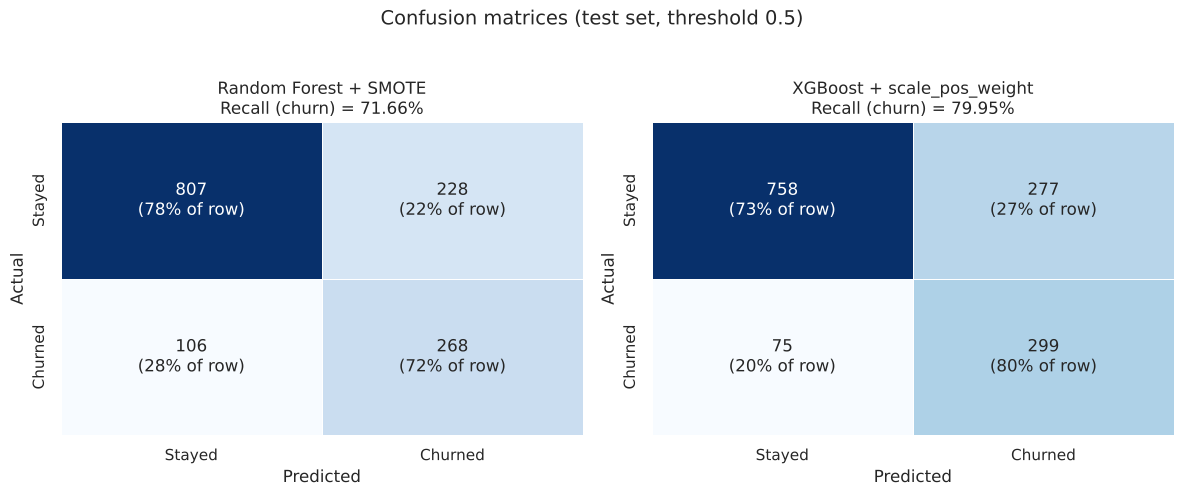

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
labels = ["Stayed", "Churned"]
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    annot = np.array([[f"{v:,}\n({v / cm[i].sum():.0%} of row)" for v in row] for i, row in enumerate(cm)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels, linewidths=0.5, linecolor="white",
                annot_kws={"size": 12})
    ax.set_title(f"{name}\nRecall (churn) = {recall_score(y_test, preds[name]):.2%}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.suptitle("Confusion matrices (test set, threshold 0.5)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

Both models catch most of the real churners (high recall) at the cost of flagging some loyal customers
(lower precision). For a retention campaign this is usually the right trade-off: a missed churner is a lost
customer, while a wrongly flagged loyal customer only receives an unnecessary offer. The threshold can be
moved to shift this balance.

## 8. Top 10 most influential features

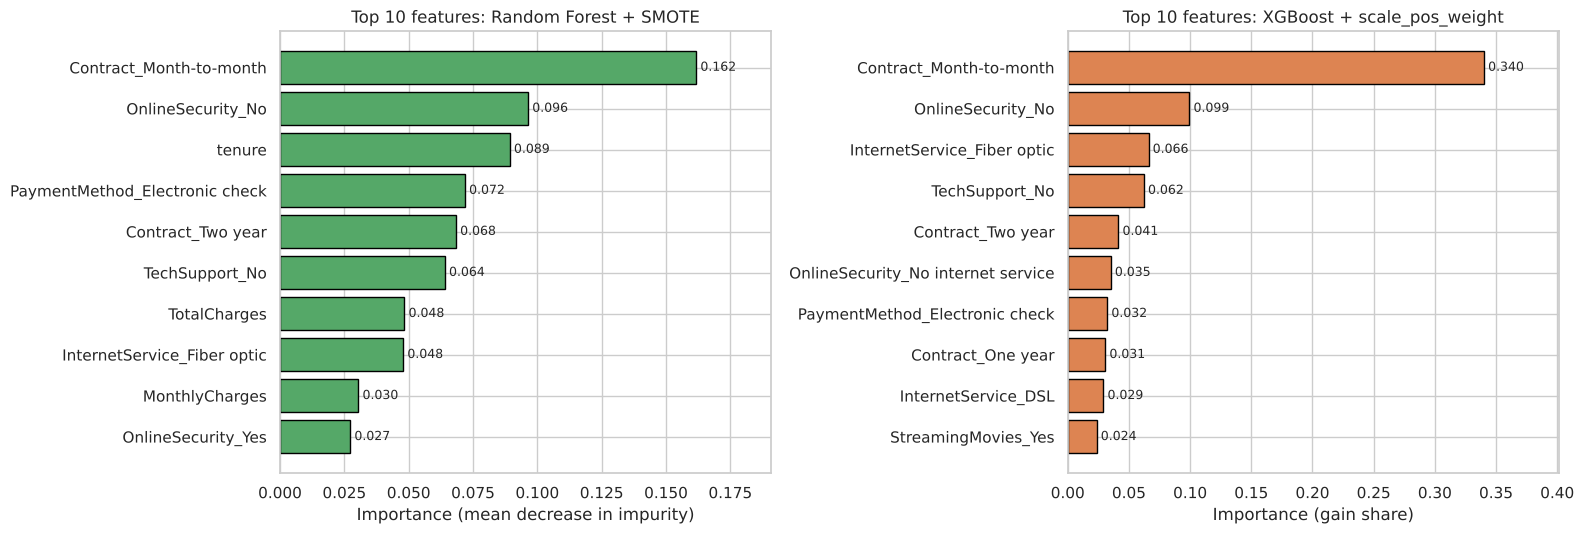

In [18]:
# Feature names after one-hot encoding, e.g. "Contract_Month-to-month"
feature_names = [f.split("__", 1)[1] for f in models["Random Forest + SMOTE"].named_steps["prep"].get_feature_names_out()]

importances = pd.DataFrame({
    name: model.named_steps["model"].feature_importances_ for name, model in models.items()
}, index=feature_names)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, name in zip(axes, models):
    top10 = importances[name].sort_values(ascending=False).head(10).sort_values()
    bars = ax.barh(top10.index, top10.values, color=colors[name], edgecolor="black")
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set_title(f"Top 10 features: {name}")
    ax.set_xlabel("Importance" + (" (mean decrease in impurity)" if "Forest" in name else " (gain share)"))
    ax.set_xlim(0, top10.max() * 1.18)
plt.tight_layout()
plt.show()

In [19]:
# Side-by-side ranking table
top_tables = {name: importances[name].sort_values(ascending=False).head(10).index.tolist() for name in models}
pd.DataFrame(top_tables, index=range(1, 11)).rename_axis("Rank")

,Random Forest + SMOTE,XGBoost + scale_pos_weight
Rank,,
1,Contract_Month-to-month,Contract_Month-to-month
2,OnlineSecurity_No,OnlineSecurity_No
3,tenure,InternetService_Fiber optic
4,PaymentMethod_Electronic check,TechSupport_No
5,Contract_Two year,Contract_Two year
6,TechSupport_No,OnlineSecurity_No internet service
7,TotalCharges,PaymentMethod_Electronic check
8,InternetService_Fiber optic,Contract_One year
9,MonthlyCharges,InternetService_DSL


Both models rank a **month-to-month contract** and **no online security** as the top two churn signals, and both
include **fiber optic internet**, **no tech support**, **payment by electronic check** and the **two-year contract**
in their top 10. The Random Forest also relies on the numeric features (**tenure**, total and monthly charges),
while XGBoost spreads importance across more of the service indicators. All of these match the patterns found in
the EDA.

## 9. Performance summary

In [20]:
summary = results.join(cv_results[["CV ROC-AUC mean", "CV ROC-AUC std"]])
print(summary.round(4).to_string())
best = summary["ROC-AUC"].idxmax()
print(f"\nBest model by test ROC-AUC: {best} ({summary.loc[best, 'ROC-AUC']:.4f})")

                            ROC-AUC  Accuracy  Precision (churn)  Recall (churn)  F1 (churn)  CV ROC-AUC mean  CV ROC-AUC std
Model                                                                                                                        
Random Forest + SMOTE        0.8376    0.7630             0.5403          0.7166      0.6161           0.8438          0.0091
XGBoost + scale_pos_weight   0.8468    0.7502             0.5191          0.7995      0.6295           0.8493          0.0113

Best model by test ROC-AUC: XGBoost + scale_pos_weight (0.8468)


**Summary**
- Cleaning: 11 blank `TotalCharges` values belonged to brand-new customers (tenure 0) and were set to 0.
- Imbalance (about 26.5% churners) was handled in two different ways: **SMOTE** oversampling for the Random Forest
  and **`scale_pos_weight`** class weighting for XGBoost. Both were applied only to training data.
- Both models were tuned with 5-fold stratified cross-validation, and both **exceed the 0.80 ROC-AUC target** on
  the untouched test set, with cross-validation scores close to the test scores (no sign of overfitting).
  Exact values are in the table above.
- The most influential features are contract type, the security / support add-ons, internet service type,
  payment method and tenure, which gives a retention team clear levers: move customers to longer contracts,
  target new fiber customers, and promote automatic payments and support bundles.

**Possible next steps**
- Tune the decision threshold to match the business cost of a missed churner vs. an unnecessary offer.
- Use SHAP values to explain individual predictions.
- Try LightGBM / CatBoost or a larger hyperparameter search.